# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [3]:
# Your code/answer goes here.

How big is the state space? Give an estimate and explain it.

In [4]:
# Your code/ answer goes here.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [5]:
# Your code/ answer goes here.

## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [6]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

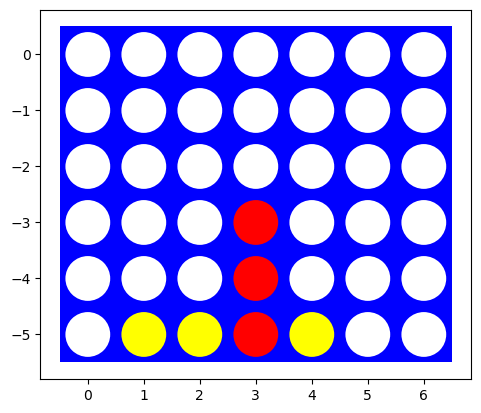

In [7]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [8]:
# Your code/ answer goes here.

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [9]:
# Your code/ answer goes here.

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [10]:
# Your code/ answer goes here.

## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [11]:
# Your code/ answer goes here.

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [12]:
# Your code/ answer goes here.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [13]:
# Your code/ answer goes here.

### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [14]:
# Your code/ answer goes here.

### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [15]:
# Your code/ answer goes here.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [16]:
# Your code/ answer goes here.

## Task 4: Heuristic Alpha-Beta Tree Search

The heuristic scores each possible four-cell window that is still uncontested: one, two, and three aligned pieces receive increasing weights, and the opponent's patterns subtract from the score. Center control is a small tie-breaker. Terminal wins/losses/draws are exactly +1/-1/0; `tanh` maps every non-terminal score strictly inside that range. The helper rules below implement the assignment's bottom-disc steal while keeping the disc's original color. A steal removes the opponent's bottom-row disc, lets that column settle, and drops the disc into a different non-full column. If one steal creates winning lines for both players at once, the state is treated as a draw because the assignment does not specify which simultaneous line takes precedence.


In [17]:
import math
import numpy as np

WIN_LENGTH = 4
_DIRECTIONS = ((0, 1), (1, 0), (1, 1), (1, -1))


def _mean_board(board):
    board = np.asarray(board)
    if board.ndim != 2 or 0 in board.shape:
        raise ValueError("board must be a non-empty 2D array")
    if not np.issubdtype(board.dtype, np.integer):
        raise TypeError("board cells must be integers")
    if not np.isin(board, (-1, 0, 1)).all():
        raise ValueError("board cells must be -1, 0, or 1")
    return board


def _mean_winners(board):
    rows, columns = board.shape
    winners = set()
    for row in range(rows):
        for column in range(columns):
            piece = int(board[row, column])
            if piece == 0:
                continue
            for row_step, column_step in _DIRECTIONS:
                end_row = row + (WIN_LENGTH - 1) * row_step
                end_column = column + (WIN_LENGTH - 1) * column_step
                if not (0 <= end_row < rows and 0 <= end_column < columns):
                    continue
                if all(board[row + i * row_step, column + i * column_step] == piece
                       for i in range(1, WIN_LENGTH)):
                    winners.add(piece)
    return winners


def _mean_actions_unchecked(board, player):
    rows, columns = board.shape
    legal = [("drop", column) for column in range(columns) if board[0, column] == 0]
    for source in range(columns):
        if board[rows - 1, source] != -player:
            continue
        for destination in range(columns):
            if destination != source and board[0, destination] == 0:
                legal.append(("steal", source, destination))
    return legal


def mean_actions(board, player):
    """List legal drops and moves of an opponent's bottom disc."""
    board = _mean_board(board)
    if isinstance(player, bool) or not isinstance(player, (int, np.integer)) or player not in (-1, 1):
        raise ValueError("player must be 1 or -1")
    if _mean_winners(board) or not np.any(board == 0):
        return []
    return _mean_actions_unchecked(board, player)


def mean_result(board, player, action):
    """Return a new board after a drop or a legal bottom-disc steal."""
    board = _mean_board(board)
    if isinstance(player, bool) or not isinstance(player, (int, np.integer)) or player not in (-1, 1):
        raise ValueError("player must be 1 or -1")
    if action not in mean_actions(board, player):
        raise ValueError(f"illegal action: {action}")
    next_board = board.copy()
    if action[0] == "drop":
        column = action[1]
        next_board[np.flatnonzero(next_board[:, column] == 0)[-1], column] = player
        return next_board

    _, source, destination = action
    stolen_piece = int(next_board[-1, source])
    next_board[1:, source] = next_board[:-1, source].copy()
    next_board[0, source] = 0
    landing_row = np.flatnonzero(next_board[:, destination] == 0)[-1]
    next_board[landing_row, destination] = stolen_piece
    return next_board


def mean_terminal(board):
    board = _mean_board(board)
    return bool(_mean_winners(board)) or not bool(np.any(board == 0))


def mean_utility(board, player):
    """Return +1/-1/0 at terminal states, else None; measured for player."""
    board = _mean_board(board)
    if isinstance(player, bool) or not isinstance(player, (int, np.integer)) or player not in (-1, 1):
        raise ValueError("player must be 1 or -1")
    winners = _mean_winners(board)
    if len(winners) > 1:
        return 0
    if winners:
        return 1 if player in winners else -1
    if not np.any(board == 0):
        return 0
    return None


def heuristic_evaluation(board, player=1):
    """Evaluate a state from player's perspective, with values in [-1, 1]."""
    board = _mean_board(board)
    if isinstance(player, bool) or not isinstance(player, (int, np.integer)) or player not in (-1, 1):
        raise ValueError("player must be 1 or -1")
    outcome = mean_utility(board, player)
    if outcome is not None:
        return float(outcome)

    rows, columns = board.shape
    weights = {1: 1.0, 2: 6.0, 3: 30.0}
    score = 0.0
    for row in range(rows):
        for column in range(columns):
            for row_step, column_step in _DIRECTIONS:
                end_row = row + (WIN_LENGTH - 1) * row_step
                end_column = column + (WIN_LENGTH - 1) * column_step
                if not (0 <= end_row < rows and 0 <= end_column < columns):
                    continue
                window = [int(board[row + i * row_step, column + i * column_step])
                          for i in range(WIN_LENGTH)]
                own_count = window.count(player)
                opponent_count = window.count(-player)
                if opponent_count == 0 and own_count:
                    score += weights[own_count]
                elif own_count == 0 and opponent_count:
                    score -= weights[opponent_count]

    center = (columns - 1) / 2
    for column in range(columns):
        center_weight = 1.0 - abs(column - center) / (center + 1.0)
        score += 0.2 * center_weight * int(np.sum(board[:, column] == player))
        score -= 0.2 * center_weight * int(np.sum(board[:, column] == -player))

    return math.tanh(score / max(12.0, rows * columns * 3.0))

### Cutting off search

Alpha-beta explores to a configurable ply depth, evaluates leaves with the bounded heuristic, and orders children by their heuristic values to expose promising cutoffs early. `HeuristicAlphaBetaAgent` stores its depth and per-move node count; it can be called as `(board, player)` like the other agents.


In [18]:
from numbers import Integral
from time import perf_counter


class HeuristicAlphaBetaAgent:
    def __init__(self, depth=3):
        if isinstance(depth, bool) or not isinstance(depth, Integral) or depth < 1:
            raise ValueError("depth must be a positive integer")
        self.depth = int(depth)
        self.nodes = 0
        self.last_elapsed = 0.0

    def __call__(self, board, player=1):
        board = _mean_board(board)
        if isinstance(player, bool) or not isinstance(player, (int, np.integer)) or player not in (-1, 1):
            raise ValueError("player must be 1 or -1")
        legal_actions = mean_actions(board, player)
        if not legal_actions:
            raise ValueError("agent cannot move from a terminal state")

        self.nodes = 0
        started = perf_counter()

        def search(state, to_move, remaining_depth, alpha, beta):
            self.nodes += 1
            outcome = mean_utility(state, player)
            if outcome is not None:
                return float(outcome)
            if remaining_depth == 0:
                return heuristic_evaluation(state, player)

            children = [
                (heuristic_evaluation(child, player), action, child)
                for action in mean_actions(state, to_move)
                for child in (mean_result(state, to_move, action),)
            ]
            maximizing = to_move == player
            children.sort(key=lambda item: item[0], reverse=maximizing)
            best_value = -math.inf if maximizing else math.inf
            for _, _, child in children:
                value = search(child, -to_move, remaining_depth - 1, alpha, beta)
                if maximizing:
                    best_value = max(best_value, value)
                    alpha = max(alpha, best_value)
                else:
                    best_value = min(best_value, value)
                    beta = min(beta, best_value)
                if alpha >= beta:
                    break
            return best_value

        ranked = []
        for action in legal_actions:
            child = mean_result(board, player, action)
            value = search(child, -player, self.depth - 1, -math.inf, math.inf)
            ranked.append((value, action))
        self.last_elapsed = perf_counter() - started
        return max(ranked, key=lambda item: item[0])[1]


# A simple function-form agent is convenient for code expecting an agent function.
def heuristic_alpha_beta_player(board, player=1, depth=3):
    return HeuristicAlphaBetaAgent(depth=depth)(board, player)


Use the following five manually constructed positions as smoke tests. They cover an empty board, immediate horizontal and vertical wins, a blocking position, and a legal steal. The assertions check both tactical choices and state/action integrity.


In [19]:
# Five targeted positions, including immediate wins and the Mean Connect 4 action.
empty = np.zeros((4, 4), dtype=int)
horizontal_win = empty.copy()
horizontal_win[-1, :3] = 1
vertical_win = empty.copy()
vertical_win[-3:, 2] = -1
blocking_position = np.zeros((4, 5), dtype=int)
blocking_position[-1, :3] = -1
steal_position = np.zeros((4, 5), dtype=int)
steal_position[-1, 0] = -1

agent = HeuristicAlphaBetaAgent(depth=2)
assert agent(empty, 1) in mean_actions(empty, 1)
assert agent(horizontal_win, 1) == ("drop", 3)
assert agent(vertical_win, -1) == ("drop", 2)
assert agent(blocking_position, 1) == ("drop", 3)
blocked = mean_result(blocking_position, 1, ("drop", 3))
assert not any(mean_utility(mean_result(blocked, -1, move), -1) == 1
               for move in mean_actions(blocked, -1))
steal_action = ("steal", 0, 1)
assert steal_action in mean_actions(steal_position, 1)
steal_result = mean_result(steal_position, 1, steal_action)
assert steal_result[-1, 0] == 0 and steal_result[-1, 1] == -1
assert np.array_equal(steal_position[-1], np.array([-1, 0, 0, 0, 0]))

scores = [heuristic_evaluation(position, side)
          for position, side in ((empty, 1), (horizontal_win, 1), (vertical_win, -1),
                                 (blocking_position, 1), (steal_position, -1))]
assert all(-1.0 <= score <= 1.0 for score in scores)
print("Five position checks passed, including immediate win and block; heuristic values:",
      [round(score, 4) for score in scores])
simultaneous_wins = np.zeros((4, 5), dtype=int)
simultaneous_wins[-1, :4] = 1
simultaneous_wins[:, 4] = -1
assert mean_terminal(simultaneous_wins)
assert mean_utility(simultaneous_wins, 1) == 0


Five position checks passed, including immediate win and block; heuristic values: [0.0, 0.6148, 0.6286, -0.598, 0.0511]


### Cutoff-depth experiment

The experiment measures first-move search cost on empty boards with four rows and increasing column counts, for several cutoffs. Node counts are reported alongside wall time so the growth in explored work is visible even when timings vary by machine. Expect more search work as either depth or branching factor increases; a deeper cutoff can improve tactical foresight but costs more time, and node counts are more portable than raw seconds.


In [20]:
from time import perf_counter

experiment_results = []
for columns in (4, 5, 6):
    position = np.zeros((4, columns), dtype=int)
    for depth in (1, 2, 3):
        player = HeuristicAlphaBetaAgent(depth=depth)
        started = perf_counter()
        move = player(position, 1)
        elapsed = perf_counter() - started
        experiment_results.append((position.shape, depth, player.nodes, elapsed, move))

print(f"{'Board':<10} {'Depth':>5} {'Nodes':>8} {'Seconds':>10} {'Selected action'}")
for shape, depth, nodes, elapsed, move in experiment_results:
    print(f"{shape[0]}x{shape[1]:<7} {depth:>5} {nodes:>8} {elapsed:>10.6f} {move}")

Board      Depth    Nodes    Seconds Selected action
4x4           1        4   0.004708 ('drop', 0)
4x4           2       32   0.033772 ('drop', 0)
4x4           3       78   0.140984 ('drop', 0)
4x5           1        5   0.003584 ('drop', 1)
4x5           2       50   0.069894 ('drop', 1)
4x5           3      151   0.282711 ('drop', 2)
4x6           1        6   0.004819 ('drop', 2)
4x6           2       72   0.080140 ('drop', 2)
4x6           3      218   0.516104 ('drop', 2)


### Playtime

A single deterministic match pits a depth-2 agent against a depth-3 agent on a 4x5 board. Because repeated bottom-disc moves can revisit positions, the experiment treats a repeated `(board, player)` state or a 100-ply cap as a draw; these safeguards only bound the demonstration and are not extra search rules.


In [21]:
def play_match(first_agent, second_agent, shape=(4, 5), max_plies=100):
    board = np.zeros(shape, dtype=int)
    player = 1
    seen = set()
    for ply in range(max_plies):
        if mean_terminal(board):
            break
        key = (board.tobytes(), player)
        if key in seen:
            return {"winner": None, "plies": ply, "reason": "repeated position"}
        seen.add(key)
        agent = first_agent if player == 1 else second_agent
        action = agent(board, player)
        board = mean_result(board, player, action)
        if mean_terminal(board):
            winner = 1 if mean_utility(board, 1) == 1 else -1
            return {"winner": winner, "plies": ply + 1, "reason": "four in a row"}
        player = -player
    return {"winner": None, "plies": max_plies, "reason": "ply cap"}


match_result = play_match(HeuristicAlphaBetaAgent(depth=2),
                          HeuristicAlphaBetaAgent(depth=3))
print("Match result:", match_result)

Match result: {'winner': -1, 'plies': 26, 'reason': 'four in a row'}


## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [22]:
# Your code/ answer goes here.

### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [23]:
# Your code/ answer goes here.